In [1]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import math

def sqrt(x,y):
        return (x/y)**0.5

def soft(x,y):
        return (x/y)/(1+x/y)

def ln(x,y):
        return math.log(1+x/y)

In [2]:
h5_file = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/h5_files/ttbb_tthbb_minorbk_non_semilep_tthbb_genmatched_all_train_4693051.h5"

In [3]:
f = h5py.File(h5_file, 'r')
f.keys()

<KeysViewHDF5 ['CLASSIFICATIONS', 'INPUTS', 'TARGETS', 'WEIGHTS']>

In [4]:
f['CLASSIFICATIONS']["EVENT"].keys()
signal  = f["CLASSIFICATIONS"]["EVENT"]['signal'][()]

In [5]:
f['INPUTS'].keys()

<KeysViewHDF5 ['Event', 'Jet', 'Lepton', 'Met']>

In [6]:
f['TARGETS'].keys()

<KeysViewHDF5 ['h', 't1', 't2']>

In [7]:
weights = f["WEIGHTS"]["weight"]

In [8]:
sum(weights[()]<0)

67308

(array([   2.,   32.,  307.,  965., 1509., 1073.,  487.,  166.,   38.,
           5.]),
 array([ 1.,  4.,  7., 10., 13., 16., 19., 22., 25., 28., 31.]),
 <BarContainer object of 10 artists>)

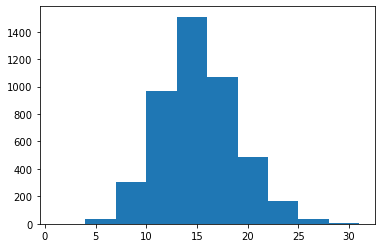

In [8]:
batch_size = 1024
num_batches = int(np.ceil(len(weights) / batch_size))

# Count negatives in each batch
negative_counts = []
for i in range(num_batches):
    batch = weights[i * batch_size : (i + 1) * batch_size]
    count_negatives = np.sum(batch < 0)
    negative_counts.append(count_negatives)

# Convert to a numpy array if you want
negative_counts = np.array(negative_counts)

plt.hist(negative_counts)

(array([9.0000e+00, 3.0000e+00, 3.0000e+00, 5.0000e+00, 5.0000e+00,
        9.0000e+00, 6.0000e+00, 1.9000e+01, 1.2000e+01, 1.7000e+01,
        1.4000e+01, 9.0000e+00, 1.3000e+01, 1.4000e+01, 1.6000e+01,
        2.4000e+01, 3.0000e+01, 3.0000e+01, 3.3000e+01, 6.2000e+01,
        7.1000e+01, 1.0000e+02, 1.6100e+02, 2.2100e+02, 4.3600e+02,
        1.2660e+03, 4.5230e+03, 5.9940e+03, 9.0510e+03, 4.4894e+04]),
 array([-0.5       , -0.48333332, -0.46666667, -0.44999999, -0.43333334,
        -0.41666666, -0.40000001, -0.38333333, -0.36666667, -0.34999999,
        -0.33333334, -0.31666666, -0.30000001, -0.28333333, -0.26666668,
        -0.25      , -0.23333333, -0.21666667, -0.2       , -0.18333334,
        -0.16666667, -0.15000001, -0.13333334, -0.11666667, -0.1       ,
        -0.08333334, -0.06666667, -0.05      , -0.03333334, -0.01666667,
         0.        ]),
 <BarContainer object of 30 artists>)

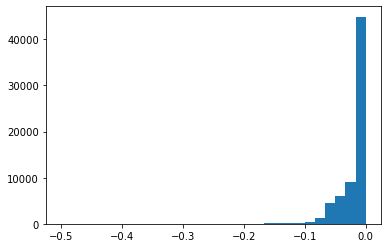

In [9]:
plt.hist(weights[()], range=(-0.5,0),bins=30)

In [10]:
event_counts = dict()
class_index = signal[:]
classes = np.unique(class_index)
for i in range(len(classes)):
    event_counts[i+1] = weights[class_index == (i + 1)].sum()

In [11]:
classes

array([1, 2, 3, 4, 5, 6])

In [12]:
#mapping_encoding:
#  signal:
#    TTH_Hto2B: 1
#    ttB: 2
#    ttC: 3
#    ttLF: 4
#    WJetsToLNu: 5
#    TTLL_ML_to50: 6
#    TTLL_ML_50: 6
#    TTNuNu: 6
#    TTLNu: 6
#    TTZ: 6
#    TWminus: 7
#    TWplus: 7

In [13]:
event_counts

{1: 907.4487,
 2: 24518.93,
 3: 19454.545,
 4: 66335.08,
 5: 650.0912,
 6: 3115.9531}

In [14]:
n_tot_events = sum(event_counts.values())
n_tot_sample = len(weights)

In [15]:
n_tot_events

114982.04577636719

In [16]:
n_tot_sample

4693051

In [17]:
factor = dict()
rescaled_weights = dict()

for key in event_counts.keys():
    w = weights[class_index == key] 
    factor[key] = n_tot_sample/event_counts[key]
    rescaled_weights[key] =  w[~np.isnan(w)]* factor[key]

In [18]:
factor

{1: 5171.698237514494,
 2: 191.40521465717018,
 3: 241.23160006292713,
 4: 70.74765165960223,
 5: 7219.065720760703,
 6: 1506.1365854147757}

In [19]:
rescaled_weights

{1: array([4.290977  , 0.20913503, 0.1676425 , ..., 2.5532072 , 0.10672478,
        0.33768296], dtype=float32),
 2: array([ 0.77449965,  9.407453  ,  8.159501  , ..., 11.37346   ,
        11.271561  ,  4.3282638 ], dtype=float32),
 3: array([ 14.036027 ,   6.4780936, -18.388584 , ...,  13.641577 ,
         11.159292 ,  38.535828 ], dtype=float32),
 4: array([3.4057944, 1.3574965, 0.8588115, ..., 4.3773084, 6.015791 ,
        2.5522833], dtype=float32),
 5: array([ 80.38291  , 486.01907  , 116.53683  , ...,  -3.5602612,
         77.04389  , 306.13843  ], dtype=float32),
 6: array([81.27471  , 38.858932 ,  6.685973 , ..., 64.33566  , 48.250595 ,
         6.5433445], dtype=float32)}

In [20]:
for key, values in rescaled_weights.items():
    print(f'{key}: mean = {np.mean(values)}, std = {np.std(values)}')

1: mean = 3.116936445236206, std = 4.257778167724609
2: mean = 6.414093971252441, std = 47.55965805053711
3: mean = 8.356377601623535, std = 15.280981063842773
4: mean = 2.7665281295776367, std = 4.867011547088623
5: mean = 51.243690490722656, std = 411.30596923828125
6: mean = 44.2127571105957, std = 71.44213104248047


In [16]:
f['TARGETS'].keys()

<KeysViewHDF5 ['h', 't1', 't2']>

In [27]:
t2 = f['TARGETS']['t2']['b'][()].tolist()
assigned_t2 = sum(1 for num in t2 if num != -1)
assigned_t2

0

In [28]:
t1 = f['TARGETS']['t1']['b'][()].tolist()
assigned_t1 = sum(1 for num in t1 if num != -1)
assigned_t1

0

In [90]:
h5_file = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/non_semileptonic_tthbb_export/h5_files_prova/tthbb_semilep_genmatched_2022_postEE_train_422624.h5"

In [91]:
f = h5py.File(h5_file, 'r+')

In [92]:
f['TARGETS'].keys()
t2 = f['TARGETS']['h']['b1'][()].tolist()
assigned_t2 = sum(1 for num in t2 if num != -1)
assigned_t2

414871

In [93]:
f['TARGETS']['t1']['q1']

<HDF5 dataset "q1": shape (422624,), type "<i8">

In [94]:
t2=f["TARGETS/t1/q2"][:]

In [95]:
sum(1 for num in t2 if num != -1)


153594

In [99]:
merged_file = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/non_semileptonic_tthbb_export/h5_files/tthbb_genmatched_ttbb_tthbb_non_semilep_train_4353783.h5"
f = h5py.File(h5_file, 'r+')
f['TARGETS'].keys()
t2 = f['TARGETS']['h']['b1'][()].tolist()
assigned_t2 = sum(1 for num in t2 if num != -1)
assigned_t2
non_assigned_t2 = sum(1 for num in t2 if num == -1)

In [100]:
assigned_t2, non_assigned_t2

(414871, 7753)